# Systemy AI – Laboratorium 7
## Zadanie: klasyfikator softmax w PyTorch – pingwiny

Napisz samodzielnie w PyTorch klasyfikator softmax, który rozpoznaje **gatunek pingwina** (Adelie, Chinstrap, Gentoo) na podstawie **dwóch** cech: długości i wysokości dzioba. Znasz te dane z Lab 4 – tym razem nie używasz gotowego `fit`, tylko sam(a) piszesz pętlę uczenia. Wzoruj się na notatniku `SystemyAI_Lab7_wzor.ipynb`.

Dwie cechy wybraliśmy celowo: wynik da się narysować na płaszczyźnie, a zadanie nie jest trywialne (Adelie i Chinstrap częściowo na siebie nachodzą).

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Dane → tensory
1. Wczytaj `sns.load_dataset("penguins")`, zostaw wiersze bez braków w `bill_length_mm`, `bill_depth_mm`, `species`.
2. Zamień gatunki na liczby: `gatunki = ["Adelie", "Chinstrap", "Gentoo"]` → 0, 1, 2.
3. Podział **trzyczęściowy** (dwa razy `train_test_split`, `stratify`, `random_state=42`): najpierw 20% na test, potem z reszty 25% na walidację. Wyjdzie 204 / 69 / 69.
4. `StandardScaler` dopasowany **tylko** na train; przekształć wszystkie trzy zbiory.
5. Tensory: `X_tr`, `X_va`, `X_te` (`float32`) oraz `y_tr`, `y_va`, `y_te` (`long`).

Zbiór walidacyjny posłuży do krzywych uczenia i wyboru learning rate, testowy – raz, na końcu.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = sns.load_dataset("penguins")
df = df.dropna(subset=["bill_length_mm", "bill_depth_mm", "species"])

gatunki = ["Adelie", "Chinstrap", "Gentoo"]
X = df[["bill_length_mm", "bill_depth_mm"]].values
y = df["species"].map({g: i for i, g in enumerate(gatunki)}).values

# najpierw 20% na test, potem z reszty 25% na walidację
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_rest, y_rest, test_size=0.25, stratify=y_rest, random_state=42)

scaler = StandardScaler().fit(X_train)

X_tr = torch.tensor(scaler.transform(X_train), dtype=torch.float32)
X_va = torch.tensor(scaler.transform(X_val), dtype=torch.float32)
X_te = torch.tensor(scaler.transform(X_test), dtype=torch.float32)
y_tr = torch.tensor(y_train, dtype=torch.long)
y_va = torch.tensor(y_val, dtype=torch.long)
y_te = torch.tensor(y_test, dtype=torch.long)

print(X_tr.shape, X_va.shape, X_te.shape)

torch.Size([204, 2]) torch.Size([69, 2]) torch.Size([69, 2])


In [2]:
# TEST
assert X_tr.shape == (204, 2) and X_va.shape == (69, 2) and X_te.shape == (69, 2)
assert X_tr.dtype == torch.float32 and y_tr.dtype == torch.long
assert set(y_tr.tolist()) == {0, 1, 2}
assert torch.allclose(X_tr.mean(dim=0), torch.zeros(2), atol=1e-5), "Standaryzacja dopasowana na train"
print("1 OK")

1 OK


---
## 2. Model i strata przed uczeniem
1. `torch.manual_seed(0)`, potem `model = nn.Linear(2, 3)` i `loss_fn = nn.CrossEntropyLoss()`.
2. Policz `loss0` – stratę na zbiorze treningowym **przed** uczeniem (`.item()`).
3. Policz `p0` – prawdopodobieństwa (softmax) dla pierwszych 3 pingwinów treningowych i wypisz je.

In [3]:
torch.manual_seed(0)
model = nn.Linear(2, 3)
loss_fn = nn.CrossEntropyLoss()

with torch.no_grad():
    loss0 = loss_fn(model(X_tr), y_tr).item()
    p0 = torch.softmax(model(X_tr[:3]), dim=1)

print("strata przed uczeniem:", round(loss0, 3))
print(p0)

strata przed uczeniem: 1.53
tensor([[0.1938, 0.5522, 0.2539],
        [0.3298, 0.3845, 0.2857],
        [0.4144, 0.2371, 0.3485]])


In [4]:
# TEST
assert 0.8 < loss0 < 2.0
assert torch.allclose(p0.sum(dim=1), torch.ones(3))
print("2 OK")

2 OK


*Twoja odpowiedź:* model, który dla każdego pingwina daje wszystkim trzem gatunkom prawdopodobieństwo 1/3, ma stratę dokładnie ln 3 ≈ 1.10. Dlaczego? Czy twoja `loss0` jest blisko tej wartości?

Odpowiedź: strata to średnia z -log(p) dla prawdziwej klasy. Jeśli model każdemu gatunkowi daje 1/3, to wychodzi -log(1/3) = ln 3 ≈ 1.10. Moja loss0 to 1.53, czyli trochę więcej niż ln 3 - losowe wagi nie dają równo po 1/3, więc dla części pingwinów prawdziwa klasa dostaje małe prawdopodobieństwo, a to mocno podnosi stratę.

---
## 3. Pętla uczenia
Napisz funkcję `train(lr, epochs=100, batch_size=32, X=X_tr, seed=0, X_val=X_va)`, która:
- ustawia `torch.manual_seed(seed)` i tworzy **nowy** `nn.Linear(2, 3)`, `CrossEntropyLoss` i `optim.SGD(..., lr=lr)`,
- uczy model mini-batchami (`DataLoader` z `shuffle=True`) przez `epochs` epok,
- po każdej epoce zapisuje w słowniku `historia` trzy listy: `"train loss"` (na `X`), `"val loss"` i `"val acc"` (na `X_val`); parametry `X` i `X_val` przydadzą się w punkcie 5,
- zwraca `(model, historia)`.

Uruchom ją dla `lr=0.1` (`model_01, hist_01`) i narysuj dwa wykresy: straty train/val oraz accuracy val w funkcji epoki.

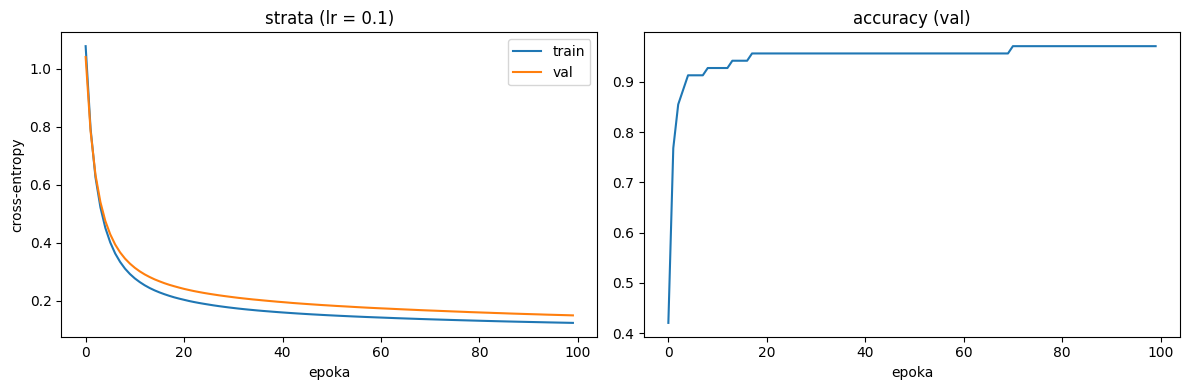

po 100 epokach: train loss 0.123, val loss 0.149, val acc 0.971


In [5]:
def train(lr, epochs=100, batch_size=32, X=X_tr, seed=0, X_val=X_va):
    torch.manual_seed(seed)
    model = nn.Linear(2, 3)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X, y_tr), batch_size=batch_size, shuffle=True)

    historia = {"train loss": [], "val loss": [], "val acc": []}
    for epoka in range(epochs):
        for xb, yb in loader:
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        with torch.no_grad():
            historia["train loss"].append(loss_fn(model(X), y_tr).item())
            out_val = model(X_val)
            historia["val loss"].append(loss_fn(out_val, y_va).item())
            historia["val acc"].append((out_val.argmax(dim=1) == y_va).float().mean().item())

    return model, historia


model_01, hist_01 = train(0.1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist_01["train loss"], label="train")
axes[0].plot(hist_01["val loss"], label="val")
axes[0].set_title("strata (lr = 0.1)")
axes[0].set_xlabel("epoka")
axes[0].set_ylabel("cross-entropy")
axes[0].legend()
axes[1].plot(hist_01["val acc"])
axes[1].set_title("accuracy (val)")
axes[1].set_xlabel("epoka")
plt.tight_layout()
plt.show()

print(f"po 100 epokach: train loss {hist_01['train loss'][-1]:.3f}, val loss {hist_01['val loss'][-1]:.3f}, val acc {hist_01['val acc'][-1]:.3f}")

In [6]:
# TEST
assert set(hist_01) == {"train loss", "val loss", "val acc"} and len(hist_01["val acc"]) == 100
assert hist_01["train loss"][-1] < hist_01["train loss"][0], "Strata powinna maleć"
assert hist_01["val acc"][-1] > 0.9
print("3 OK")

3 OK


---
## 4. Learning rate
Naucz model dla `lr` ∈ {0.001, 0.01, 0.1, 1.0}. Na jednym wykresie narysuj krzywe **straty treningowej** dla wszystkich czterech wartości, a wyniki końcowe (`val loss`, `val acc` po 100 epokach) zbierz w `pd.DataFrame` o nazwie `wyniki_lr` (indeks: wartości lr).

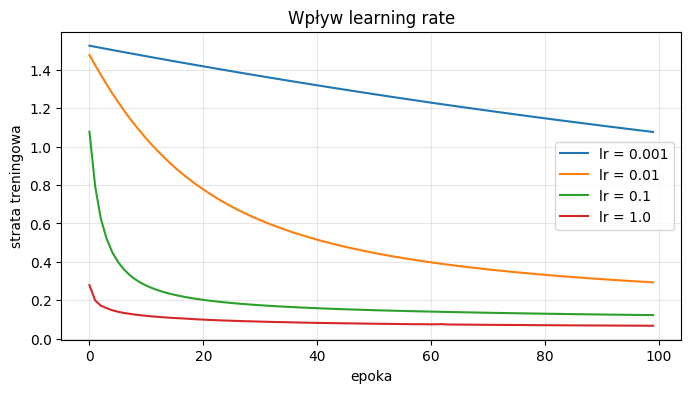

,val loss,val acc
lr,,
0.001,1.038,0.420
0.010,0.329,0.928
0.100,0.149,0.971
1.000,0.072,0.971


In [7]:
lrs = [0.001, 0.01, 0.1, 1.0]
modele = {}
wiersze = []

fig, ax = plt.subplots(figsize=(8, 4))
for lr in lrs:
    m, h = train(lr)
    modele[lr] = m
    ax.plot(h["train loss"], label=f"lr = {lr}")
    wiersze.append({"lr": lr, "val loss": h["val loss"][-1], "val acc": h["val acc"][-1]})

ax.set_xlabel("epoka")
ax.set_ylabel("strata treningowa")
ax.set_title("Wpływ learning rate")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

wyniki_lr = pd.DataFrame(wiersze).set_index("lr")
wyniki_lr.round(3)

In [8]:
# TEST
assert list(wyniki_lr.index) == [0.001, 0.01, 0.1, 1.0]
assert wyniki_lr.loc[0.001, "val loss"] > wyniki_lr.loc[0.1, "val loss"]
print("4 OK")

4 OK


*Twoja odpowiedź:* co widać dla lr = 0.001? Który learning rate wybierasz i na podstawie którego zbioru?

Odpowiedź: dla lr = 0.001 strata maleje bardzo powoli (z ok. 1.53 do ok. 1.08 po 100 epokach), a val acc to tylko 0.420 - kroki są za małe i model prawie się nie nauczył. Wybieram lr = 1.0, bo ma najmniejszą stratę na zbiorze walidacyjnym (0.072, przy val acc 0.971 - tyle samo co lr = 0.1). Wybór robię na zbiorze walidacyjnym, a nie testowym.

---
## 5. Co daje standaryzacja?
Utwórz `X_tr_raw` i `X_va_raw` – tensory **bez** standaryzacji (surowe milimetry z `X_train`, `X_val`) i naucz model z `lr=0.1`: `train(0.1, X=X_tr_raw, X_val=X_va_raw)`. Porównaj końcową stratę i accuracy z wynikiem z punktu 3. Wynik zapisz w `hist_raw`.

bez standaryzacji: val loss 29.097, val acc 0.797
ze standaryzacją:  val loss 0.149, val acc 0.971


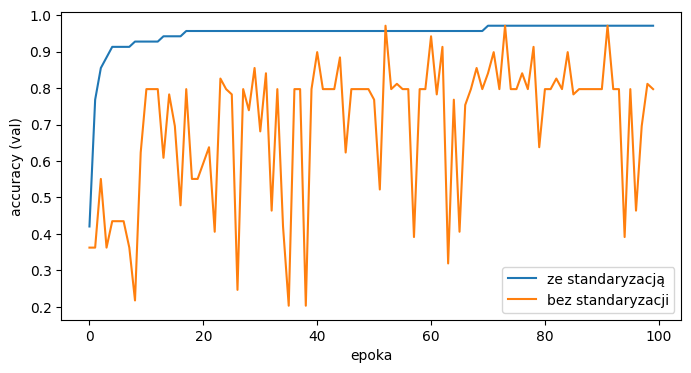

In [9]:
X_tr_raw = torch.tensor(X_train, dtype=torch.float32)
X_va_raw = torch.tensor(X_val, dtype=torch.float32)

_, hist_raw = train(0.1, X=X_tr_raw, X_val=X_va_raw)

print(f"bez standaryzacji: val loss {hist_raw['val loss'][-1]:.3f}, val acc {hist_raw['val acc'][-1]:.3f}")
print(f"ze standaryzacją:  val loss {hist_01['val loss'][-1]:.3f}, val acc {hist_01['val acc'][-1]:.3f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hist_01["val acc"], label="ze standaryzacją")
ax.plot(hist_raw["val acc"], label="bez standaryzacji")
ax.set_xlabel("epoka")
ax.set_ylabel("accuracy (val)")
ax.legend()
plt.show()

In [10]:
# TEST
assert hist_raw["val acc"][-1] < hist_01["val acc"][-1]
print("5 OK")

5 OK


*Twoja odpowiedź:* dlaczego bez standaryzacji uczenie idzie tak źle, choć model i dane są te same?

Odpowiedź: bez standaryzacji cechy mają duże wartości (dziób ok. 32-60 mm i 13-22 mm), więc gradienty są duże i przy lr = 0.1 kroki są za długie - model przeskakuje minimum. Do tego cechy mają różne skale, a jeden lr musi pasować do obu wag. Wynik: bez standaryzacji val loss 29.1 i val acc 0.797, ze standaryzacją 0.149 i 0.971.

---
## 6. Ocena końcowa i porównanie ze scikit-learn
1. Wybierz model z punktu 4 (wybór na podstawie walidacji) i zapisz go jako `model_koncowy`. Policz `acc_test` – accuracy na **teście**.
2. Naucz `LogisticRegression()` ze scikit-learn na tych samych wystandaryzowanych danych treningowych i policz jej accuracy na teście: `acc_sk`.
3. Wypisz prawdopodobieństwa (softmax) Twojego modelu dla pierwszych 5 pingwinów testowych, z nazwami gatunków i prawdziwym gatunkiem.
4. Narysuj obszary decyzyjne `model_koncowy` na płaszczyźnie (wystandaryzowane cechy) z punktami treningowymi – możesz skopiować funkcję `granica` z wzoru.

wybrany lr: 1.0
PyTorch accuracy (test): 0.957
sklearn accuracy (test): 0.928
   Adelie  Chinstrap  Gentoo  predykcja     prawda
0   0.969      0.031   0.000     Adelie     Adelie
1   0.983      0.017   0.000     Adelie     Adelie
2   0.000      0.005   0.995     Gentoo     Gentoo
3   0.001      0.110   0.889     Gentoo     Gentoo
4   0.087      0.909   0.004  Chinstrap  Chinstrap


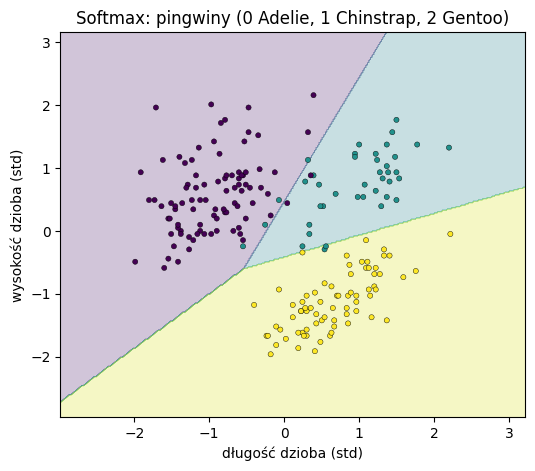

In [11]:
from sklearn.linear_model import LogisticRegression

najlepszy_lr = wyniki_lr["val loss"].idxmin()
model_koncowy = modele[najlepszy_lr]
print("wybrany lr:", najlepszy_lr)

with torch.no_grad():
    acc_test = (model_koncowy(X_te).argmax(dim=1) == y_te).float().mean().item()

sk = LogisticRegression().fit(X_tr.numpy(), y_tr.numpy())
acc_sk = sk.score(X_te.numpy(), y_te.numpy())

print(f"PyTorch accuracy (test): {acc_test:.3f}")
print(f"sklearn accuracy (test): {acc_sk:.3f}")

with torch.no_grad():
    p_test = torch.softmax(model_koncowy(X_te[:5]), dim=1)

podglad = pd.DataFrame(p_test.numpy().round(3), columns=gatunki)
podglad["predykcja"] = [gatunki[i] for i in p_test.argmax(dim=1)]
podglad["prawda"] = [gatunki[i] for i in y_te[:5]]
print(podglad)


def granica(model, X, y, tytul, softmax=False):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 300),
                         np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 300))
    siatka = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
    with torch.no_grad():
        out = model(siatka)
        Z = out.argmax(dim=1) if softmax else (out > 0).squeeze(1)
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.contourf(xx, yy, Z.reshape(xx.shape).numpy(), alpha=0.25, cmap="viridis")
    ax.scatter(X[:, 0], X[:, 1], c=y, s=14, cmap="viridis", edgecolors="k", linewidths=0.3)
    ax.set_title(tytul)
    ax.set_xlabel("długość dzioba (std)")
    ax.set_ylabel("wysokość dzioba (std)")
    plt.show()


granica(model_koncowy, X_tr.numpy(), y_tr.numpy(), "Softmax: pingwiny (0 Adelie, 1 Chinstrap, 2 Gentoo)", softmax=True)

In [12]:
# TEST
assert 0.85 < acc_test <= 1.0
assert abs(acc_test - acc_sk) <= 0.06, "Ten sam model - wyniki powinny być bardzo podobne"
assert torch.allclose(p_test.sum(dim=1), torch.ones(5))
print("6 OK")

6 OK


*Twoja odpowiedź:*
1. Jak wypada Twój model w porównaniu ze scikit-learn? Czy to zaskakujące?
2. Gdzie leżą błędy modelu na wykresie obszarów decyzyjnych? Czy model liniowy mógłby tu zrobić coś lepiej?
3. Wymień kroki pętli uczenia i powiedz jednym zdaniem, co robi każdy z nich.

Odpowiedź:
1. Mój model ma na teście accuracy 0.957, a LogisticRegression ze scikit-learn 0.928. Różnica to ok. 3 p.p., czyli 2 pingwiny (1 pingwin to ok. 1.4 p.p.). To nie jest zaskakujące - to ten sam model (liniowy softmax), tylko uczony innym algorytmem i w sklearn z regularyzacją, więc wyniki są bardzo podobne.
2. Błędy leżą na granicy Adelie i Chinstrap - kilka punktów jednego gatunku wchodzi w obszar drugiego, bo mają podobną wysokość dzioba. Model liniowy rysuje tylko proste granice, więc tych punktów nie rozdzieli. Pomogłyby dodatkowe cechy albo model nieliniowy.
3. Kroki pętli uczenia:

 1)forward (model(xb)) - model liczy logity dla porcji danych,

2)strata (loss_fn) - sprawdzamy, jak bardzo przewidywania różnią się od prawdziwych gatunków,

3)zero_grad() - zerujemy gradienty z poprzedniego kroku, bo PyTorch je sumuje,

4)backward() - autograd liczy gradient straty po wszystkich wagach,

5)step() - optymalizator przesuwa wagi o mały krok w stronę przeciwną do gradientu.

---
## 7. Dla chętnych
1. **Batch size:** naucz model z `lr=0.1` dla `batch_size` ∈ {8, 32, 204} (204 = cały zbiór naraz). Porównaj krzywe straty. Który wariant robi najwięcej kroków w epoce? Który uczy się najszybciej w przeliczeniu na epoki?
2. **Adam:** zamień `optim.SGD` na `optim.Adam` (lr = 0.01) i porównaj krzywe z SGD.
3. **Więcej cech:** dodaj `flipper_length_mm` i `body_mass_g` (`nn.Linear(4, 3)`). Ile zyskuje accuracy?

7.1 Batch size:

batch   8: kroków w epoce 26, train loss po 10 epokach 0.164, po 100 0.085
batch  32: kroków w epoce  7, train loss po 10 epokach 0.292, po 100 0.123
batch 204: kroków w epoce  1, train loss po 10 epokach 0.932, po 100 0.241


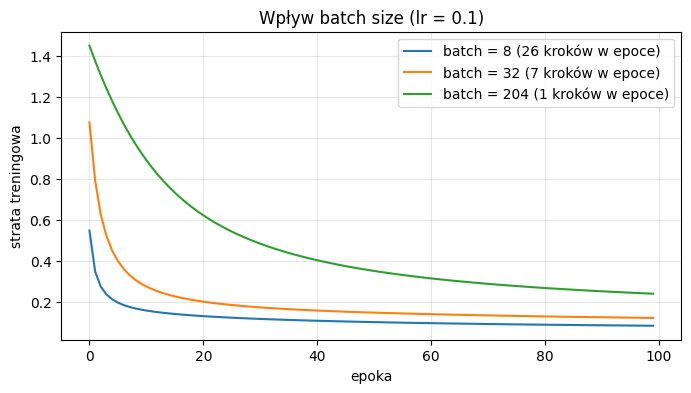

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
for bs in [8, 32, 204]:
    _, h = train(0.1, batch_size=bs)
    kroki = int(np.ceil(204 / bs))
    ax.plot(h["train loss"], label=f"batch = {bs} ({kroki} kroków w epoce)")
    print(f"batch {bs:3d}: kroków w epoce {kroki:2d}, train loss po 10 epokach {h['train loss'][9]:.3f}, po 100 {h['train loss'][-1]:.3f}")

ax.set_xlabel("epoka")
ax.set_ylabel("strata treningowa")
ax.set_title("Wpływ batch size (lr = 0.1)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

7.2 Adam:

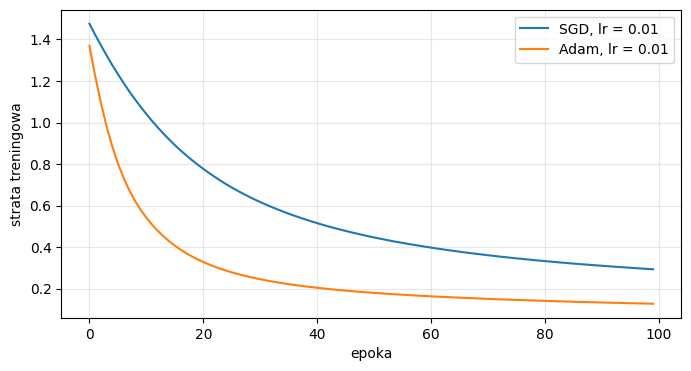

SGD:  train loss 0.294, val acc 0.928
Adam: train loss 0.128, val acc 0.971


In [14]:
def train_opt(lr, opt_cls, X=X_tr, X_val=X_va, n_cech=2, epochs=100, batch_size=32, seed=0):
    torch.manual_seed(seed)
    model = nn.Linear(n_cech, 3)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = opt_cls(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X, y_tr), batch_size=batch_size, shuffle=True)

    historia = {"train loss": [], "val loss": [], "val acc": []}
    for epoka in range(epochs):
        for xb, yb in loader:
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        with torch.no_grad():
            historia["train loss"].append(loss_fn(model(X), y_tr).item())
            out_val = model(X_val)
            historia["val loss"].append(loss_fn(out_val, y_va).item())
            historia["val acc"].append((out_val.argmax(dim=1) == y_va).float().mean().item())
    return model, historia


_, h_sgd = train_opt(0.01, optim.SGD)
_, h_adam = train_opt(0.01, optim.Adam)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(h_sgd["train loss"], label="SGD, lr = 0.01")
ax.plot(h_adam["train loss"], label="Adam, lr = 0.01")
ax.set_xlabel("epoka")
ax.set_ylabel("strata treningowa")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

print(f"SGD:  train loss {h_sgd['train loss'][-1]:.3f}, val acc {h_sgd['val acc'][-1]:.3f}")
print(f"Adam: train loss {h_adam['train loss'][-1]:.3f}, val acc {h_adam['val acc'][-1]:.3f}")

7.3 Więcej cech:

In [15]:
cechy4 = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
df4 = sns.load_dataset("penguins").dropna(subset=cechy4 + ["species"])
X4 = df4[cechy4].values
y4 = df4["species"].map({g: i for i, g in enumerate(gatunki)}).values

X4_rest, X4_test, y4_rest, y4_test = train_test_split(X4, y4, test_size=0.2, stratify=y4, random_state=42)
X4_train, X4_val, y4_train, y4_val = train_test_split(X4_rest, y4_rest, test_size=0.25, stratify=y4_rest, random_state=42)
print("ten sam podział co wcześniej:", (y4_train == y_train).all() and (y4_val == y_val).all())

scaler4 = StandardScaler().fit(X4_train)
X4_tr = torch.tensor(scaler4.transform(X4_train), dtype=torch.float32)
X4_va = torch.tensor(scaler4.transform(X4_val), dtype=torch.float32)

_, h4 = train_opt(0.1, optim.SGD, X=X4_tr, X_val=X4_va, n_cech=4)
print(f"2 cechy: val acc {hist_01['val acc'][-1]:.3f}, val loss {hist_01['val loss'][-1]:.3f}")
print(f"4 cechy: val acc {h4['val acc'][-1]:.3f}, val loss {h4['val loss'][-1]:.3f}")

ten sam podział co wcześniej: True
2 cechy: val acc 0.971, val loss 0.149
4 cechy: val acc 0.971, val loss 0.066


Odpowiedź:
1. Najwięcej kroków w epoce robi batch = 8 (26 kroków), batch = 32 robi 7, a cały zbiór (204) tylko 1. Dlatego batch = 8 uczy się najszybciej w przeliczeniu na epoki: po 10 epokach strata to 0.164, przy batch = 32 - 0.292, a przy 204 aż 0.932.
2. Adam przy tym samym lr = 0.01 uczy się dużo szybciej niż SGD: po 100 epokach strata 0.128 zamiast 0.294 i val acc 0.971 zamiast 0.928. Adam sam dopasowuje długość kroku dla każdej wagi.
3. Accuracy się nie zmieniła (0.971 dla 2 i 4 cech - na 69 pingwinach w obu przypadkach 2 błędy), ale val loss spadł z 0.149 do 0.066, czyli model z 4 cechami jest dużo pewniejszy swoich odpowiedzi.